<div style="background: linear-gradient(135deg,#1a3c64,#0d7377);
            padding:30px; border-radius:15px; text-align:center; color:white;">
  <h1>Projet : Detection masked face & unmasking </h1>
  <h2>Visualisation 3D des Architectures de Modèles</h2>
   <div style="text-align:center;">
<h3 style="color:white; font-family:'Trebuchet MS', sans-serif;">

---

**Réalisé par :** Ihsane Foudal - Hiba Gourri - Hajar Bellafrouh

**Encadré par:** Mr. Yazid Safiny

--IID2--

</h3>
</div>

 
</div>
visualiser les architectures de tous les modèles
utilisés dans ce projet via `visualkeras`.

L'image produite montre chaque couche du réseau sous forme de bloc 3D :
la hauteur/largeur = taille des feature maps, la profondeur = nombre de filtres.

### Modèles visualisés :

| Modèle | Fichier | Rôle |
|---|---|---|
| **VGG16** | `vgg16_best.keras` | Classification MASK / NO MASK |
| **Générateur U-Net** | `pix2pix_generator.h5` | Démasquage — génère le visage |
| **Discriminateur PatchGAN** | `pix2pix_discriminator.h5` | Démasquage — juge vrai/faux |

### Légende des couleurs :
| Couleur | Type de couche |
|---|---|
| 🔴 Rouge | Conv2D — extraction de features |
| ⬛ Gris foncé | MaxPooling — réduction spatiale |
| 🔵 Bleu | BatchNormalization — stabilisation |
| 🟢 Vert | Dense / GlobalAvgPooling — classification |
| 🟠 Orange | Dropout / Add / Concatenate |
| 🟣 Violet | Conv2DTranspose — décodeur U-Net |

 INSTALLATION DE VISUALKERAS

In [1]:
# ══════════════════════════════════════════════════════════════
#  INSTALLATION DE VISUALKERAS
# ══════════════════════════════════════════════════════════════
import subprocess
subprocess.run(['pip', 'install', 'visualkeras', '-q'],
               capture_output=True)

import visualkeras
import tensorflow as tf
from tensorflow.keras.models import load_model
from tensorflow.keras import layers as KL
from collections import defaultdict
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

print(f"✅ visualkeras prêt")
print(f"✅ TensorFlow : {tf.__version__}")

# ─── Dossier de sortie ───────────────────────────────────────
OUTPUT_DIR = Path('./architectures')
OUTPUT_DIR.mkdir(exist_ok=True)
print(f"✅ Dossier : {OUTPUT_DIR.resolve()}")

✅ visualkeras prêt
✅ TensorFlow : 2.21.0
✅ Dossier : D:\projet_tuto_architect\architectures


 Palette de couleurs

In [2]:
# ══════════════════════════════════════════════════════════════
#  PALETTE DE COULEURS PAR TYPE DE COUCHE
# ══════════════════════════════════════════════════════════════

color_map = defaultdict(
    lambda: {'fill': '#DDDDDD', 'outline': '#AAAAAA'}
)

# Convolutions → rouge
color_map[KL.Conv2D]                 = {'fill': '#E74C3C', 'outline': '#922B21'}
color_map[KL.Conv2DTranspose]        = {'fill': '#8E44AD', 'outline': '#5B2C6F'}
color_map[KL.DepthwiseConv2D]        = {'fill': '#E74C3C', 'outline': '#922B21'}

# Pooling → gris
color_map[KL.MaxPooling2D]           = {'fill': '#555555', 'outline': '#222222'}
color_map[KL.AveragePooling2D]       = {'fill': '#777777', 'outline': '#333333'}
color_map[KL.GlobalAveragePooling2D] = {'fill': '#1ABC9C', 'outline': '#148F77'}

# Dense → vert
color_map[KL.Dense]                  = {'fill': '#27AE60', 'outline': '#1A6B3A'}

# Régularisation → orange
color_map[KL.Dropout]                = {'fill': '#F39C12', 'outline': '#B7770D'}
color_map[KL.BatchNormalization]     = {'fill': '#3498DB', 'outline': '#1A5276'}

# Merge → orange
color_map[KL.Add]                    = {'fill': '#E67E22', 'outline': '#935116'}
color_map[KL.Concatenate]            = {'fill': '#E67E22', 'outline': '#935116'}

# Autres
color_map[KL.Flatten]                = {'fill': '#9B59B6', 'outline': '#6C3483'}
color_map[KL.ZeroPadding2D]          = {'fill': '#BDC3C7', 'outline': '#808B96'}
color_map[KL.InputLayer]             = {'fill': '#2980B9', 'outline': '#1A5276'}
color_map[KL.Activation]             = {'fill': '#F1C40F', 'outline': '#B7950B'}
color_map[KL.LeakyReLU]             = {'fill': '#F1C40F', 'outline': '#B7950B'}

print("✅ Palette de couleurs configurée")

✅ Palette de couleurs configurée


---
##  Architecture 1 — VGG16 (Classification Mask / No Mask)

VGG16 est composé de 5 blocs convolutifs suivis d'une tête de classification
personnalisée pour notre tâche binaire mask/no_mask.

On charge le modèle sauvegardé `vgg16_best.keras` et on génère
la visualisation 3D de toutes ses couches.

Chargement VGG16...
✅ VGG16 chargé : 14,880,065 paramètres
   Couches : 26
✅ Architecture VGG16 sauvegardée → architectures\architecture_vgg16.png


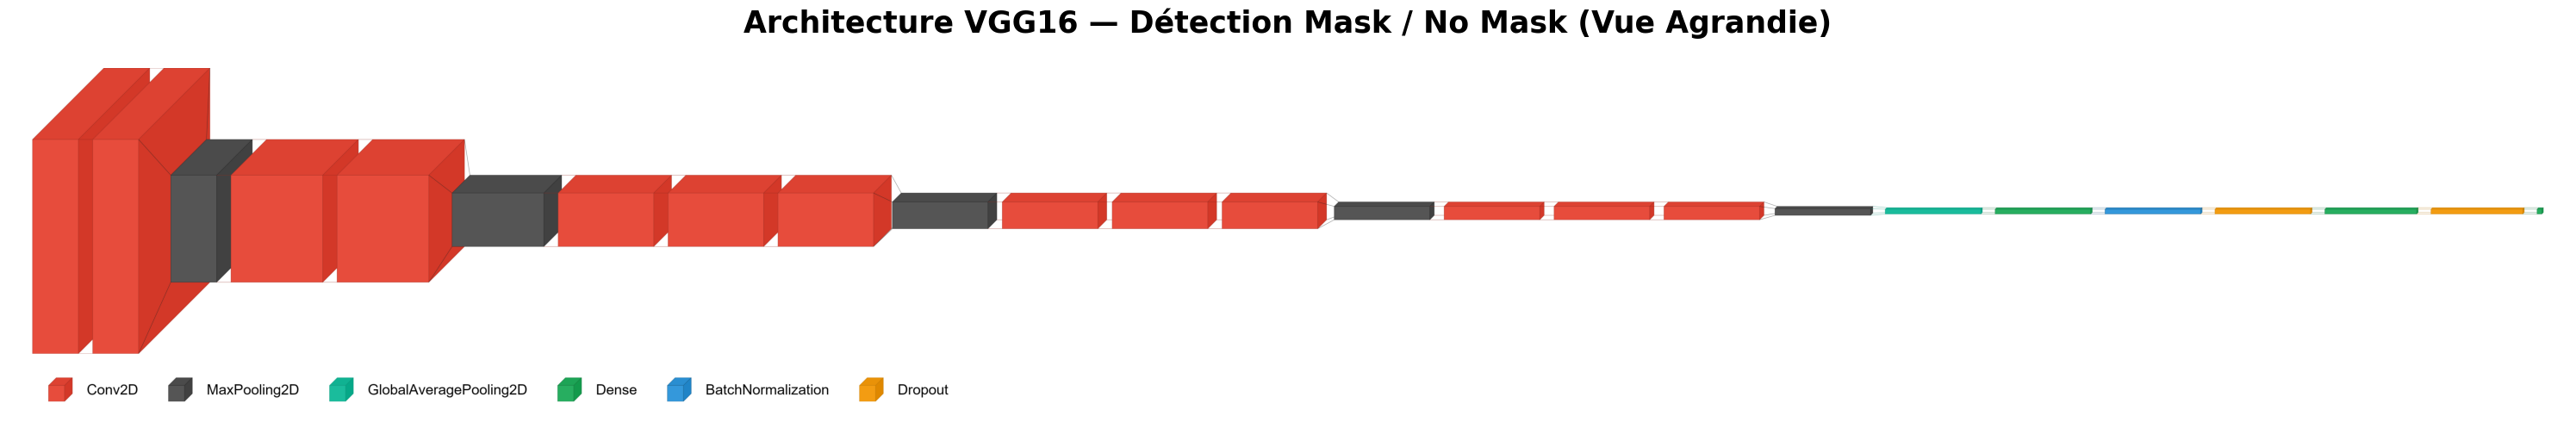

✅ Affiché avec une légende bien lisible !


In [8]:
from tensorflow.keras.layers import InputLayer
from PIL import ImageFont  # 💡 NOUVEL IMPORT : Pour gérer la taille du texte

# ══════════════════════════════════════════════════════════════
#  ARCHITECTURE VGG16
# ══════════════════════════════════════════════════════════════

# ─── Chargement du modèle sauvegardé ────────────────────────
print("Chargement VGG16...")
model_vgg16 = load_model('vgg16_best.keras', compile=False)

# 🛠️ PATCH POUR TENSORFLOW 2.21 / KERAS 3 🛠️
for layer in model_vgg16.layers:
    if not hasattr(layer, 'output_shape'):
        try:
            layer.output_shape = tuple(layer.output.shape)
        except AttributeError:
            pass
# ══════════════════════════════════════════════════════════════

print(f"✅ VGG16 chargé : {model_vgg16.count_params():,} paramètres")
print(f"   Couches : {len(model_vgg16.layers)}")

# ─── Configuration de la police (Texte Géant) ────────────────
try:
    # On charge la police Arial en taille 60 (tu peux ajuster ce chiffre)
    font = ImageFont.truetype("arial.ttf", 60)
except IOError:
    print("⚠️ Police Arial introuvable, on tente une autre...")
    font = ImageFont.load_default() # Secours si arial n'est pas sur ton PC

# ─── Génération visualkeras ──────────────────────────────────
out_path = str(OUTPUT_DIR / 'architecture_vgg16.png')

visualkeras.layered_view(
    model_vgg16,
    type_ignore=[InputLayer], 
    color_map=color_map,       
    to_file=out_path,
    legend=True,
    font=font,             # 💡 MODIFIÉ : On injecte notre grande police ici
    draw_volume=True,      
    scale_xy=4,            
    scale_z=3,             
    spacing=60,            
    background_fill='white',
    padding=100            # 💡 MODIFIÉ : Marge plus grande pour ne pas couper le gros texte
)

print(f"✅ Architecture VGG16 sauvegardée → {out_path}")

# ─── Affichage GRAND FORMAT dans VS Code ─────────────────────
fig, ax = plt.subplots(figsize=(30, 15)) 
img = mpimg.imread(out_path)
ax.imshow(img)
ax.axis('off')
ax.set_title('Architecture VGG16 — Détection Mask / No Mask (Vue Agrandie)',
             fontsize=25, fontweight='bold', pad=30) 

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'architecture_vgg16_affichage.png'),
            dpi=300, bbox_inches='tight') 
plt.show()
print("✅ Affiché avec une légende bien lisible !")

---
##  Architecture 2 — Générateur U-Net (Pix2Pix Démasquage)

Le générateur U-Net encode l'image masquée puis la décode avec des
skip connections pour reconstruire le visage original.

On charge `pix2pix_generator.h5` et on génère la visualisation.

Chargement Générateur U-Net...
✅ Générateur chargé : 54,425,859 paramètres
   Couches : 24
✅ Architecture Générateur sauvegardée → architectures\architecture_generator_unet.png


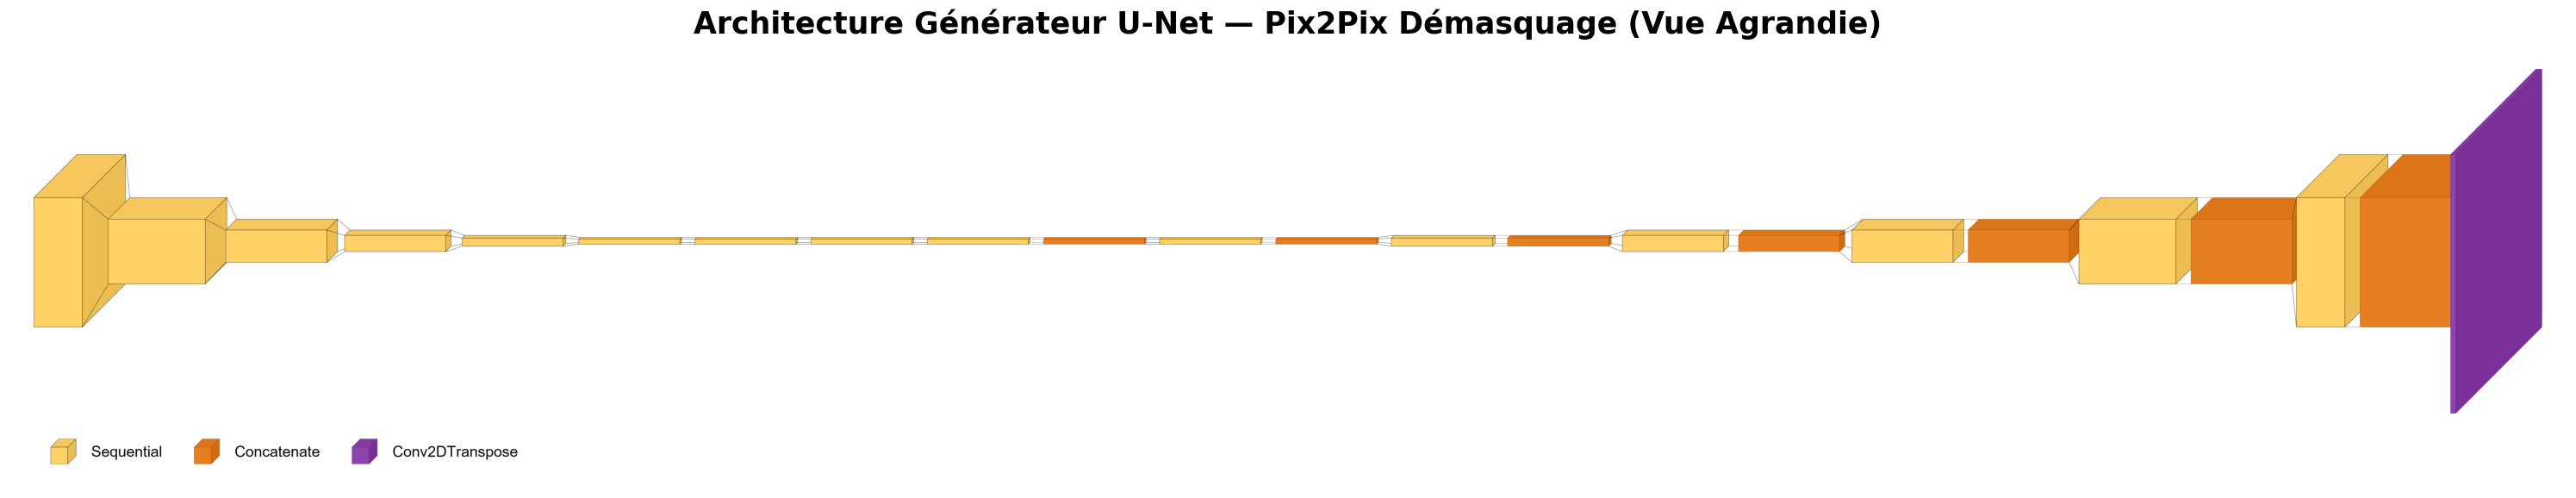

✅ Affiché en grand et tout est visible !


In [10]:
from tensorflow.keras.layers import InputLayer
from PIL import ImageFont

# ══════════════════════════════════════════════════════════════
#  ARCHITECTURE GÉNÉRATEUR U-NET (PIX2PIX)
# ══════════════════════════════════════════════════════════════

print("Chargement Générateur U-Net...")
model_gen = load_model('pix2pix_generator.h5', compile=False)

# 🛠️ PATCH POUR TENSORFLOW 2.21 / KERAS 3 🛠️
for layer in model_gen.layers:
    if not hasattr(layer, 'output_shape'):
        try:
            layer.output_shape = tuple(layer.output.shape)
        except AttributeError:
            pass
# ══════════════════════════════════════════════════════════════

print(f"✅ Générateur chargé : {model_gen.count_params():,} paramètres")
print(f"   Couches : {len(model_gen.layers)}")

# ─── Configuration de la police (Texte Géant) ────────────────
try:
    font = ImageFont.truetype("arial.ttf", 60)
except IOError:
    print("⚠️ Police Arial introuvable, on tente une autre...")
    font = ImageFont.load_default()

# ─── Génération visualkeras ──────────────────────────────────
out_path_gen = str(OUTPUT_DIR / 'architecture_generator_unet.png')

visualkeras.layered_view(
    model_gen,
    type_ignore=[InputLayer],  # 💡 On ignore la couche d'entrée
    color_map=color_map,
    to_file=out_path_gen,
    legend=True,
    font=font,                 # 💡 On applique la grande police
    draw_volume=True,
    scale_xy=4,                # 💡 Échelle augmentée pour les blocs
    scale_z=3,                 # 💡 Profondeur augmentée
    spacing=60,                # 💡 Plus d'espace entre les couches
    background_fill='white',
    padding=100                # 💡 Grande marge pour ne rien couper
)

print(f"✅ Architecture Générateur sauvegardée → {out_path_gen}")

# ─── Affichage GRAND FORMAT dans VS Code ─────────────────────
fig, ax = plt.subplots(figsize=(30, 15)) # 💡 Fenêtre très large
img = mpimg.imread(out_path_gen)
ax.imshow(img)
ax.axis('off')
ax.set_title('Architecture Générateur U-Net — Pix2Pix Démasquage (Vue Agrandie)',
             fontsize=25, fontweight='bold', pad=30)

# Assurer que la légende en bas est bien visible
plt.subplots_adjust(bottom=0.15) 

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'architecture_generator_affichage.png'),
            dpi=300, bbox_inches='tight') # 💡 Sauvegarde en Haute Définition
plt.show()
print("✅ Affiché en grand et tout est visible !")

---
## Architecture 3 — Discriminateur PatchGAN (Pix2Pix)

Le discriminateur PatchGAN reçoit deux images concaténées (masquée + générée
ou masquée + réelle) et produit une carte de scores 30×30 indiquant
si chaque patch est vrai ou faux.

On charge `pix2pix_discriminator.h5` et on génère la visualisation.

Chargement Discriminateur PatchGAN...
✅ Discriminateur chargé : 2,770,433 paramètres
   Couches : 12
✅ Architecture Discriminateur sauvegardée → architectures\architecture_discriminator_patchgan.png


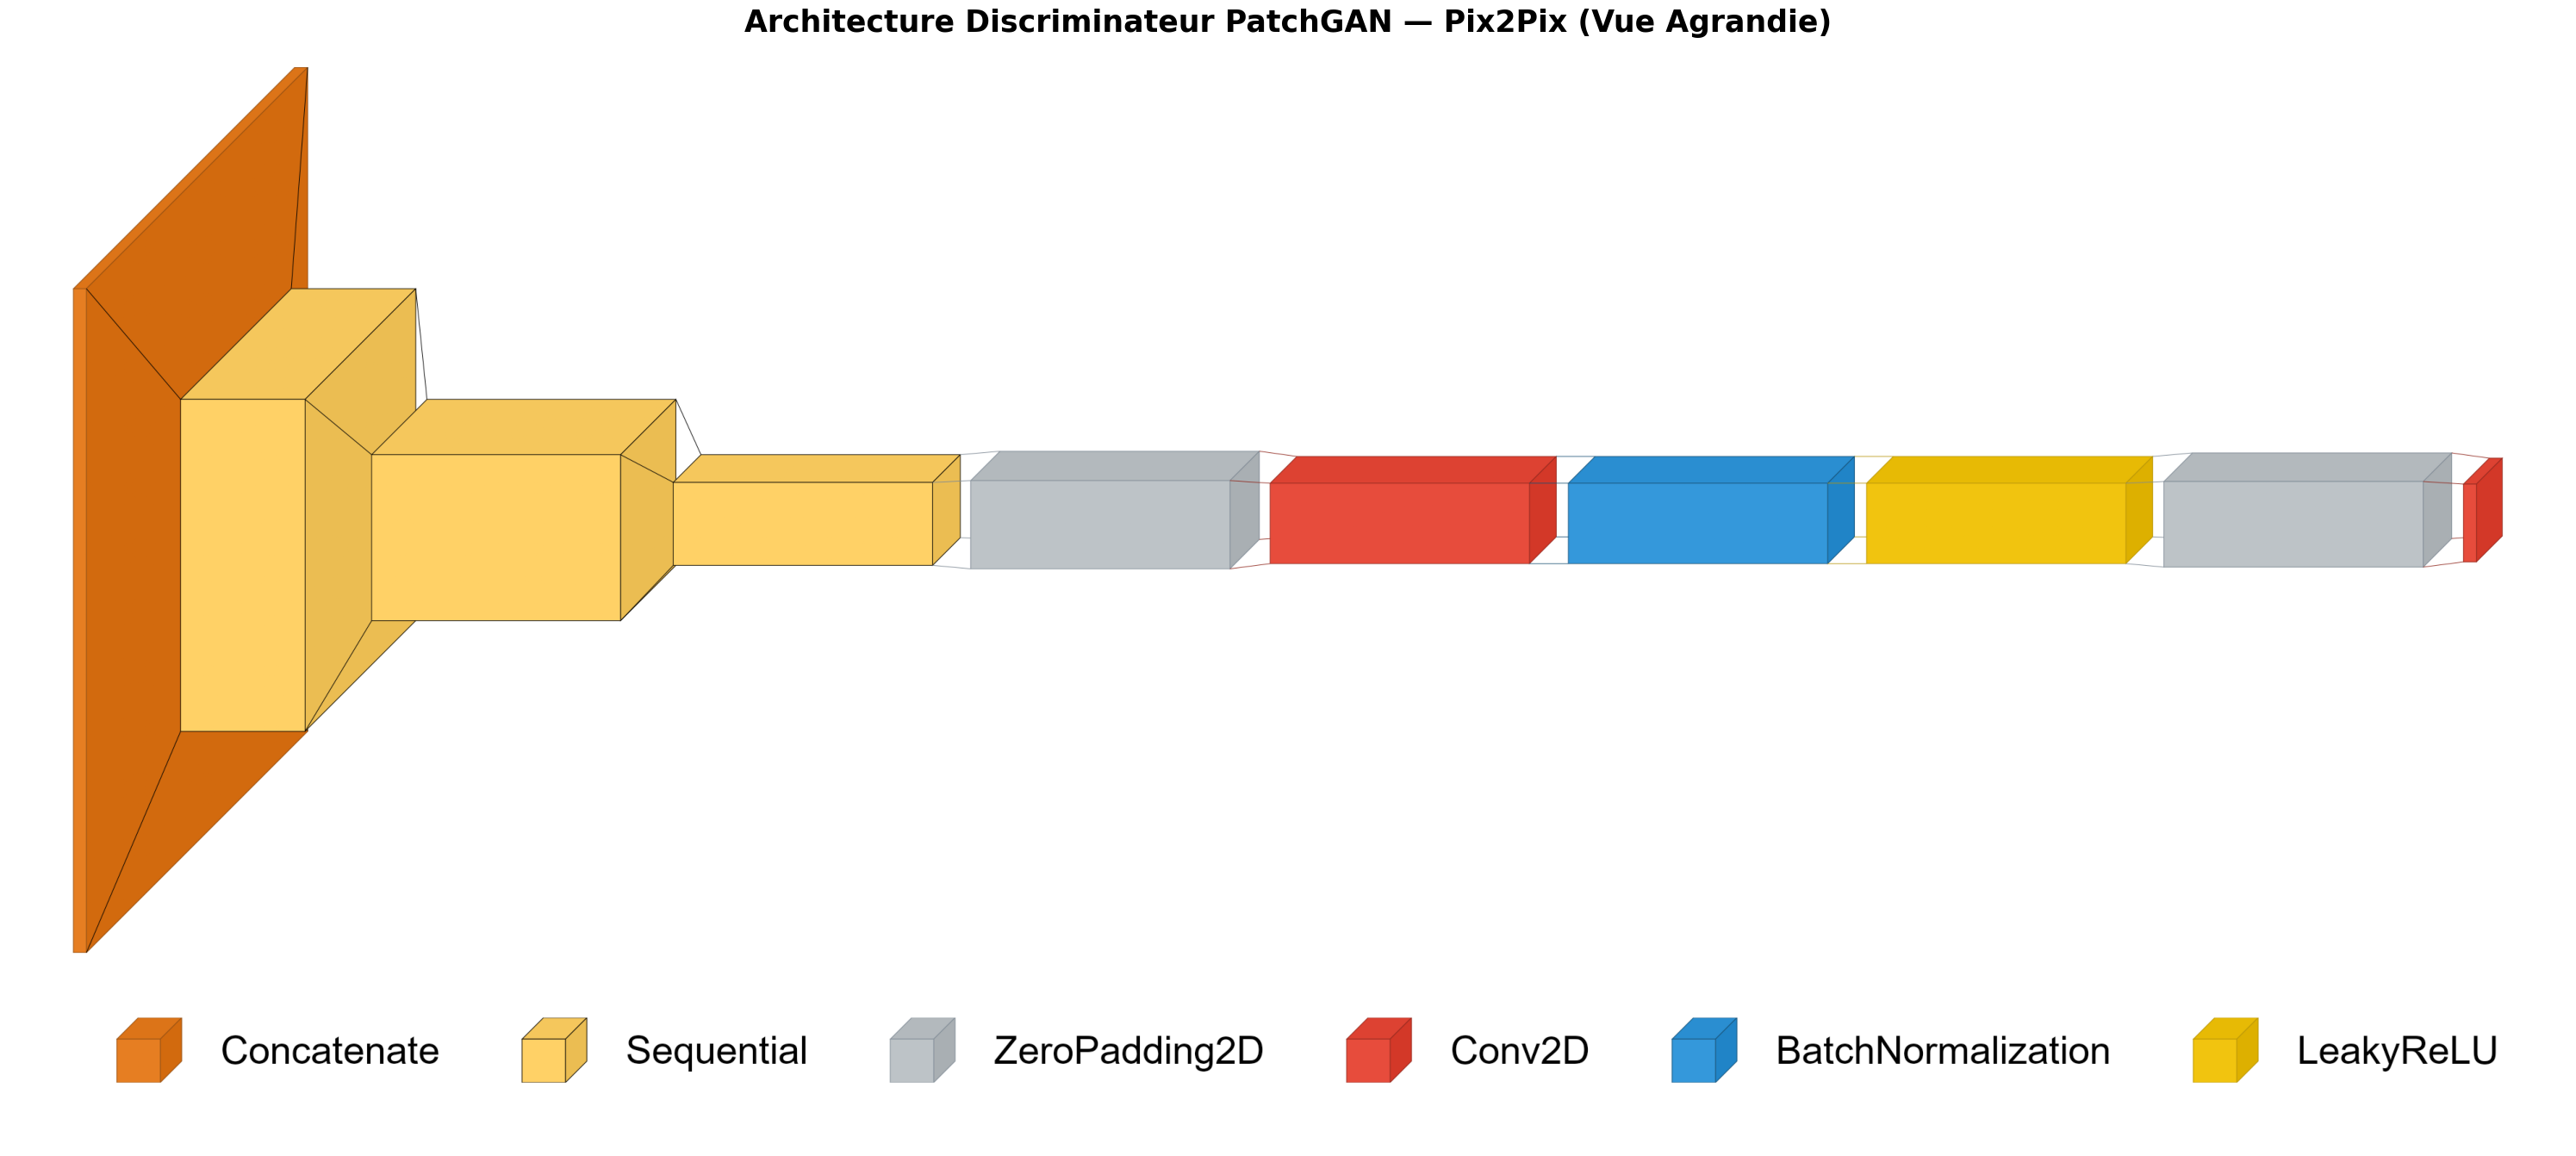

✅ Affiché en grand et tout est visible !


In [12]:
from tensorflow.keras.layers import InputLayer
from PIL import ImageFont

# ══════════════════════════════════════════════════════════════
#  ARCHITECTURE DISCRIMINATEUR PATCHGAN (PIX2PIX)
# ══════════════════════════════════════════════════════════════

print("Chargement Discriminateur PatchGAN...")
model_disc = load_model('pix2pix_discriminator.h5', compile=False)

# 🛠️ PATCH POUR TENSORFLOW 2.21 / KERAS 3 🛠️
for layer in model_disc.layers:
    if not hasattr(layer, 'output_shape'):
        try:
            layer.output_shape = tuple(layer.output.shape)
        except AttributeError:
            pass
# ══════════════════════════════════════════════════════════════

print(f"✅ Discriminateur chargé : {model_disc.count_params():,} paramètres")
print(f"   Couches : {len(model_disc.layers)}")

# ─── Configuration de la police (Texte Géant) ────────────────
try:
    font = ImageFont.truetype("arial.ttf", 60)
except IOError:
    print("⚠️ Police Arial introuvable, on tente une autre...")
    font = ImageFont.load_default()

# ─── Génération visualkeras ──────────────────────────────────
out_path_disc = str(OUTPUT_DIR / 'architecture_discriminator_patchgan.png')

visualkeras.layered_view(
    model_disc,
    type_ignore=[InputLayer],  # 💡 On ignore la couche d'entrée
    color_map=color_map,       # ⚠️ Assure-toi que color_map est toujours défini
    to_file=out_path_disc,
    legend=True,
    font=font,                 # 💡 On applique la grande police
    draw_volume=True,
    scale_xy=4,                # 💡 Échelle augmentée pour de gros blocs
    scale_z=3,                 # 💡 Profondeur augmentée
    spacing=60,                # 💡 Espace confortable entre les couches
    background_fill='white',
    padding=100                # 💡 Marge géante pour ne pas couper la légende
)

print(f"✅ Architecture Discriminateur sauvegardée → {out_path_disc}")

# ─── Affichage GRAND FORMAT dans VS Code ─────────────────────
fig, ax = plt.subplots(figsize=(30, 15)) # 💡 Fenêtre XXL
img = mpimg.imread(out_path_disc)
ax.imshow(img)
ax.axis('off')
ax.set_title('Architecture Discriminateur PatchGAN — Pix2Pix (Vue Agrandie)',
             fontsize=25, fontweight='bold', pad=30)

# Ajustement pour être sûr que le bas ne soit pas rogné
plt.subplots_adjust(bottom=0.15) 

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'architecture_discriminator_affichage.png'),
            dpi=300, bbox_inches='tight') # 💡 Sauvegarde en 300 DPI (Haute Définition)
plt.show()
print("✅ Affiché en grand et tout est visible !")

---
## Résumé Comparatif des Architectures

Tableau récapitulatif de tous les modèles utilisés dans le projet.

╔══════════════════════════════════════════════════════════════╗
║          RÉSUMÉ DES ARCHITECTURES DU PROJET                ║
╠══════════════════════════════════════════════════════════════╣
║  VGG16 (classif.)  : 14,880,065 paramètres          ║
║  U-Net Générateur  : 54,425,859 paramètres          ║
║  PatchGAN Discrim. :  2,770,433 paramètres          ║
╠══════════════════════════════════════════════════════════════╣
║  TOTAL             : 72,076,357 paramètres          ║
╚══════════════════════════════════════════════════════════════╝


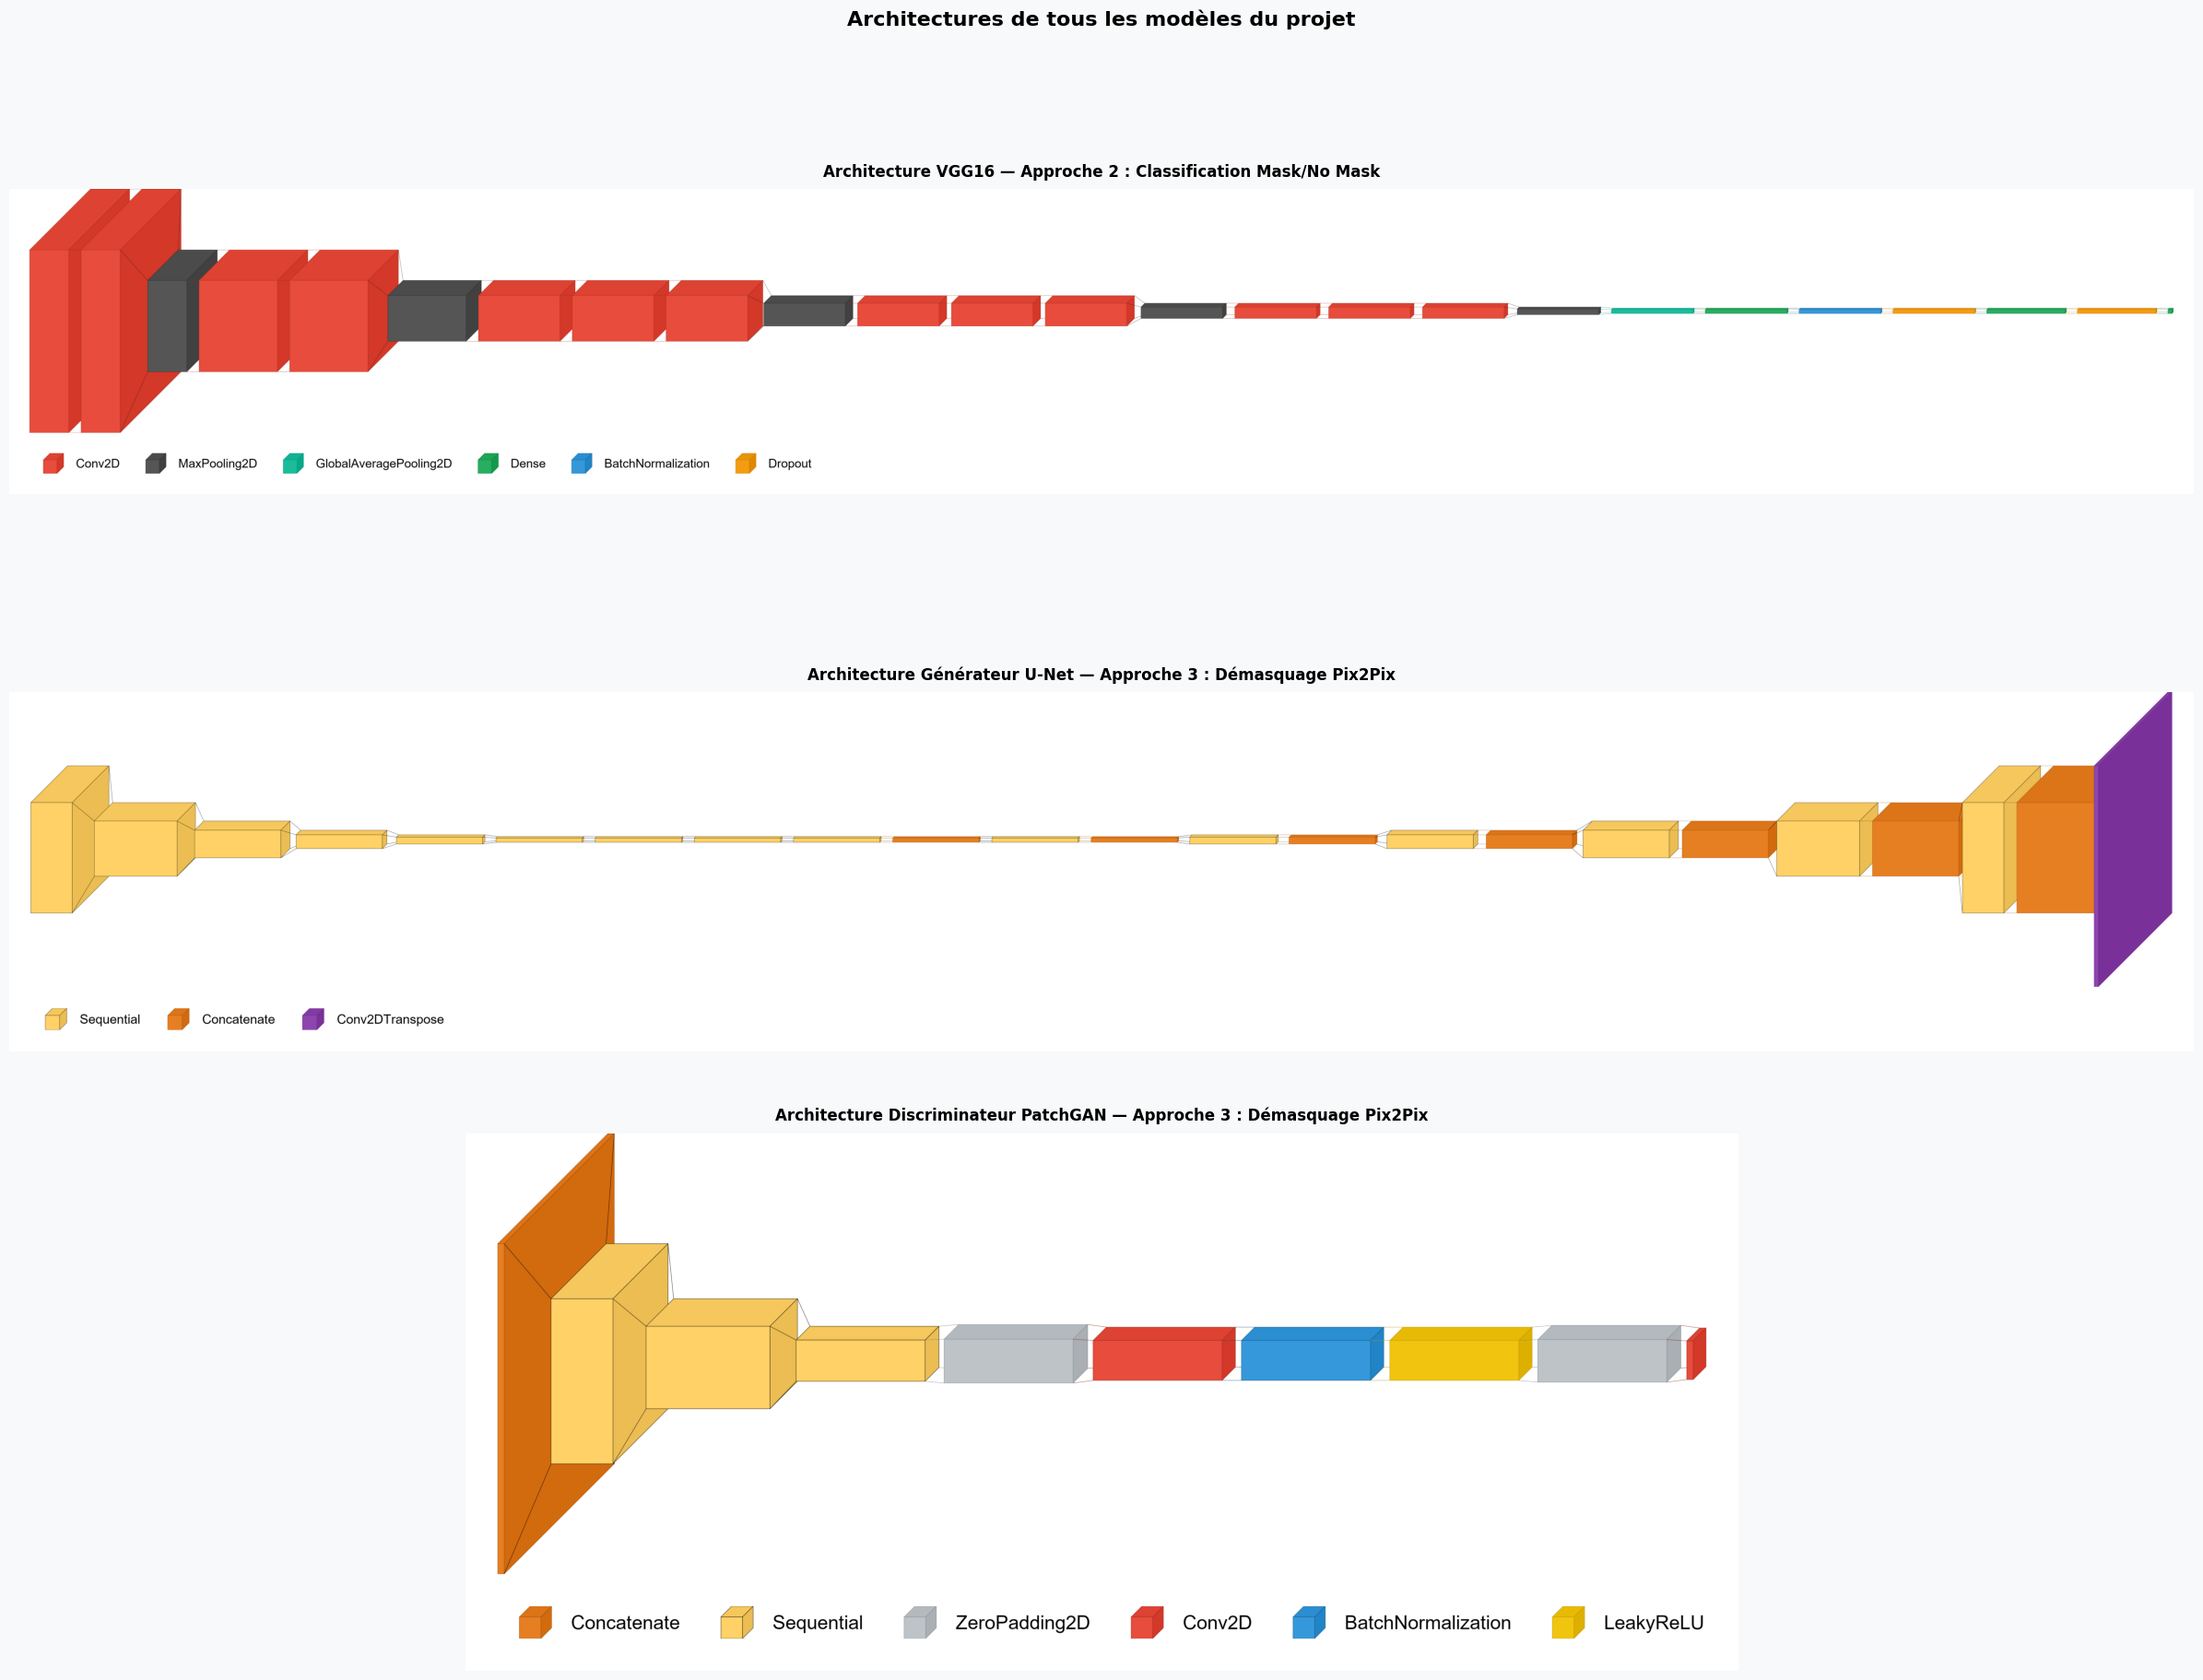


✅ Toutes les architectures générées et sauvegardées dans :
   architecture_discriminator_affichage.png             1357 KB
   architecture_discriminator_patchgan.png                98 KB
   architecture_generator_affichage.png                  317 KB
   architecture_generator_unet.png                       171 KB
   architecture_vgg16.png                                183 KB
   architecture_vgg16_affichage.png                      330 KB
   toutes_architectures.png                              188 KB


In [13]:
# ══════════════════════════════════════════════════════════════
#  RÉSUMÉ COMPARATIF + AFFICHAGE CÔTE À CÔTE
# ══════════════════════════════════════════════════════════════

print("╔══════════════════════════════════════════════════════════════╗")
print("║          RÉSUMÉ DES ARCHITECTURES DU PROJET                ║")
print("╠══════════════════════════════════════════════════════════════╣")
print(f"║  VGG16 (classif.)  : {model_vgg16.count_params():>10,} paramètres          ║")
print(f"║  U-Net Générateur  : {model_gen.count_params():>10,} paramètres          ║")
print(f"║  PatchGAN Discrim. : {model_disc.count_params():>10,} paramètres          ║")
print("╠══════════════════════════════════════════════════════════════╣")
total = (model_vgg16.count_params() +
         model_gen.count_params() +
         model_disc.count_params())
print(f"║  TOTAL             : {total:>10,} paramètres          ║")
print("╚══════════════════════════════════════════════════════════════╝")

# ─── Affichage côte à côte des 3 architectures ───────────────
fig, axes = plt.subplots(3, 1, figsize=(24, 18))
fig.patch.set_facecolor('#f8f9fa')
fig.suptitle('Architectures de tous les modèles du projet',
             fontsize=16, fontweight='bold', y=1.01)

titles = [
    ('Architecture VGG16 — Approche 2 : Classification Mask/No Mask',
     str(OUTPUT_DIR / 'architecture_vgg16.png')),
    ('Architecture Générateur U-Net — Approche 3 : Démasquage Pix2Pix',
     str(OUTPUT_DIR / 'architecture_generator_unet.png')),
    ('Architecture Discriminateur PatchGAN — Approche 3 : Démasquage Pix2Pix',
     str(OUTPUT_DIR / 'architecture_discriminator_patchgan.png')),
]

for ax, (title, path) in zip(axes, titles):
    img = mpimg.imread(path)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(title, fontsize=12, fontweight='bold', pad=10)

plt.tight_layout()
plt.savefig(str(OUTPUT_DIR / 'toutes_architectures.png'),
            dpi=120, bbox_inches='tight')
plt.show()

print("\n✅ Toutes les architectures générées et sauvegardées dans :")
for f in sorted(OUTPUT_DIR.iterdir()):
    size = f.stat().st_size / 1024
    print(f"   {f.name:50s} {size:6.0f} KB")